## What Drives Website Visits? Three ML Models

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

sys.path.insert(0, "../src")
from uplift import make_features

df = pd.read_csv("../data/hillstrom.csv")
X = make_features(df)
X["mens_email"] = (df["segment"] == "Mens E-Mail").astype(int)
X["womens_email"] = (df["segment"] == "Womens E-Mail").astype(int)
y = df["visit"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print(X_tr.shape, X_te.shape)
X.head()

(44800, 11) (19200, 11)


,recency,history,mens,womens,newbie,zip_code_Surburban,zip_code_Urban,channel_Phone,channel_Web,mens_email,womens_email
0,10,142.44,1,0,0,1,0,1,0,0,1
1,6,329.08,1,1,1,0,0,0,1,0,0
2,7,180.65,0,1,1,1,0,0,1,0,1
3,9,675.83,1,0,1,0,0,0,1,1,0
4,2,45.34,1,0,0,0,1,0,1,0,1


In [2]:
models = {
    "Logistic regression (baseline)": LogisticRegression(max_iter=2000),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42),
}
auc = {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    auc[name] = roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])
pd.Series(auc, name="Test ROC AUC").round(3)

Logistic regression (baseline)    0.648
Decision tree (depth 4)           0.618
XGBoost                           0.648
Name: Test ROC AUC, dtype: float64

## Model comparison
Test ROC AUC: logistic regression 0.648, decision tree 0.618, XGBoost 0.648. XGBoost matched but did not beat the simple baseline, which tells us the extra complexity is not worth it with these few features: the relationships are mostly simple and additive. The shallow decision tree did worst because a 4-level flowchart is too coarse. With equal accuracy, logistic regression is the better choice because each coefficient can be explained to a business audience, which is what the next section does.

In [3]:
logit = models["Logistic regression (baseline)"]
odds = pd.Series(np.exp(logit.coef_[0]), index=X.columns, name="odds ratio").sort_values()
print("history, per $100 spent:", round(np.exp(logit.coef_[0][list(X.columns).index("history")] * 100), 2))
odds.round(2)

history, per $100 spent: 1.04


newbie                0.58
zip_code_Urban        0.68
zip_code_Surburban    0.71
channel_Phone         0.87
recency               0.95
history               1.00
channel_Web           1.14
womens_email          1.51
mens                  1.77
mens_email            1.89
womens                2.07
Name: odds ratio, dtype: float64

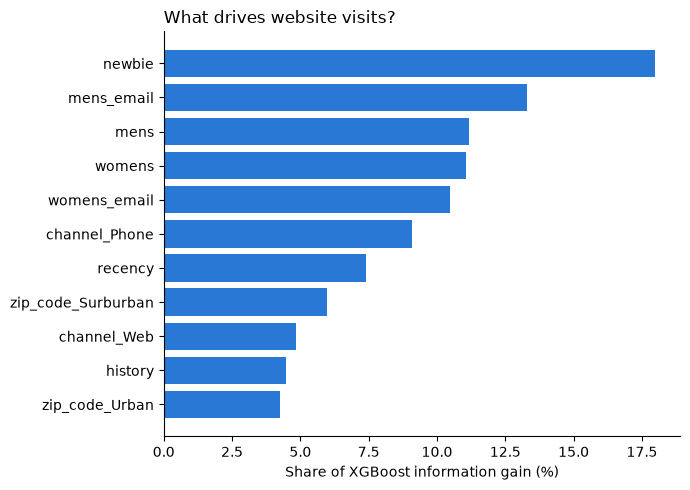

newbie                18.0
mens_email            13.3
mens                  11.2
womens                11.0
womens_email          10.5
channel_Phone          9.1
recency                7.4
zip_code_Surburban     6.0
channel_Web            4.8
history                4.5
zip_code_Urban         4.3
dtype: float64

In [4]:
xgb = models["XGBoost"]
imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).reindex(X.columns).fillna(0)
imp = (imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values * 100, color="#2a78d6")
ax.set_xlabel("Share of XGBoost information gain (%)")
ax.set_title("What drives website visits?", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/02_visit_drivers.png", dpi=150)
plt.show()
(imp * 100).round(1).sort_values(ascending=False)

## What drives visits
The top three drivers in XGBoost were newbie (18.0% of gain), the men's email (13.3%), and past men's purchases (11.2%). The men's email multiplied visit odds by 1.89 and the women's email by 1.51 (logistic regression); these are the only drivers we can call causal because the emails were randomly assigned. Customer history matters even more in total (about 52% of XGBoost's gain): new customers have 42% lower visit odds, each extra month since the last purchase lowers odds about 5%, and past buyers of women's (2.07x) or men's (1.77x) merchandise are much more likely to visit. Rural customers visit more than urban or suburban ones. Like the original tutorial, which found website traffic source mattered more than the experiment, this shows the email matters, but so does who the customer already is. That raises the next question: which customers does the email help most?